# Step 7: Model Evaluation

In [2]:
# Import evaluation functions and load saved models and data

from pathlib import Path
import sys
import joblib
import pandas as pd

current_folder = Path.cwd().resolve()
project_root = (
    current_folder.parent
    if current_folder.name == "notebooks"
    else current_folder
)

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.evaluation.metrics import calculate_classification_metrics
from src.evaluation.confusion_matrix import save_confusion_matrix

models_folder = project_root / "models"
split_folder = project_root / "data" / "processed" / "splits"

X_test = pd.read_csv(split_folder / "X_test.csv")
y_test = pd.read_csv(
    split_folder / "y_test.csv"
).squeeze("columns")

logistic_pipeline = joblib.load(
    models_folder / "logistic_regression_pipeline.joblib"
)

random_forest_pipeline = joblib.load(
    models_folder / "random_forest_pipeline.joblib"
)

xgboost_pipeline = joblib.load(
    models_folder / "xgboost_pipeline.joblib"
)

hybrid_ensemble = joblib.load(
    models_folder / "weighted_soft_voting_ensemble.joblib"
)

print("Models and test data loaded.")

Models and test data loaded.


In [3]:
# Evaluate all models on the untouched test set

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgboost_pipeline,
    "Weighted Soft-Voting Ensemble": hybrid_ensemble
}

test_results = []

for model_name, model in models.items():
    predictions = model.predict(X_test)

    result = calculate_classification_metrics(
        y_true=y_test,
        y_pred=predictions,
        model_name=model_name,
        split_name="test"
    )

    test_results.append(result)

test_results_df = pd.DataFrame(test_results)

display(test_results_df)

,model,split,accuracy,precision,recall,f1_score,tn,fp,fn,tp
0,Logistic Regression,test,0.886369,0.902989,0.859840,0.880886,23599,2285,3467,21269
1,Random Forest,test,0.967938,0.977088,0.956824,0.966850,25329,555,1068,23668
2,XGBoost,test,0.967068,0.982837,0.949183,0.965717,25474,410,1257,23479
3,Weighted Soft-Voting Ensemble,test,0.967819,0.982381,0.951205,0.966541,25462,422,1207,23529


In [4]:
# Save final test metrics and confusion-matrix figures

metrics_folder = project_root / "results" / "metrics"
confusion_folder = project_root / "results" / "confusion_matrices"

metrics_folder.mkdir(parents=True, exist_ok=True)
confusion_folder.mkdir(parents=True, exist_ok=True)

test_metrics_path = metrics_folder / "final_test_metrics.csv"
test_results_df.to_csv(test_metrics_path, index=False)

for model_name, model in models.items():
    predictions = model.predict(X_test)

    output_path = save_confusion_matrix(
        y_true=y_test,
        y_pred=predictions,
        model_name=model_name,
        output_folder=confusion_folder
    )

    print(f"{model_name}: {output_path}")

print("\nTest metrics saved to:")
print(test_metrics_path)

Logistic Regression: C:\Users\Jiya\Documents\Malicious URL Detection\results\confusion_matrices\logistic_regression_confusion_matrix.png
Random Forest: C:\Users\Jiya\Documents\Malicious URL Detection\results\confusion_matrices\random_forest_confusion_matrix.png
XGBoost: C:\Users\Jiya\Documents\Malicious URL Detection\results\confusion_matrices\xgboost_confusion_matrix.png
Weighted Soft-Voting Ensemble: C:\Users\Jiya\Documents\Malicious URL Detection\results\confusion_matrices\weighted_soft-voting_ensemble_confusion_matrix.png

Test metrics saved to:
C:\Users\Jiya\Documents\Malicious URL Detection\results\metrics\final_test_metrics.csv


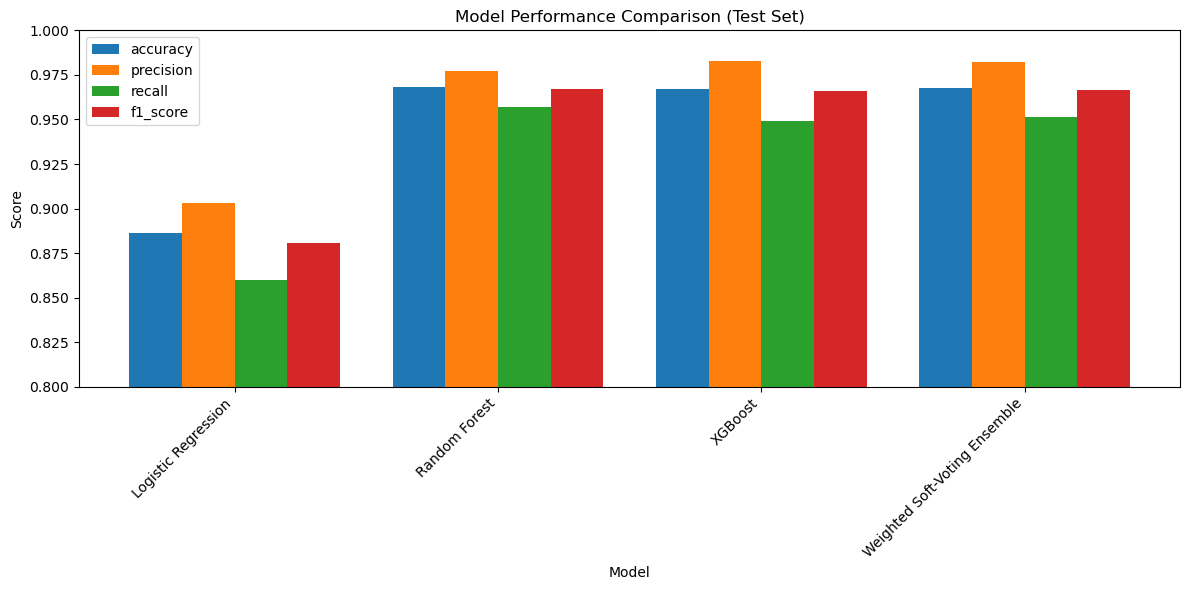

Model comparison chart saved!


In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Make sure data is loaded (re-run if needed)
# If test_results_df doesn't exist, run Cell 1 & 2 first!

# Model comparison bar chart
fig, ax = plt.subplots(figsize=(12, 6))

models = test_results_df['model'].tolist()
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

x = np.arange(len(models))
width = 0.2

for i, metric in enumerate(metrics):
    values = test_results_df[metric].tolist()
    ax.bar(x + (i * width), values, width, label=metric)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison (Test Set)')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.legend()
ax.set_ylim([0.8, 1.0])

plt.tight_layout()
plt.savefig(project_root / "results/figures/model_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print("Model comparison chart saved!")

In [9]:
# Check what class labels the models use
print("Logistic Regression classes:", logistic_pipeline.classes_)
print("Random Forest classes:", random_forest_pipeline.classes_)
print("XGBoost classes:", xgboost_pipeline.classes_)

# Check y_test values
print("\nUnique labels in y_test:", y_test.unique())
print("First 5 y_test values:", y_test.head())

Logistic Regression classes: [0 1]
Random Forest classes: [0 1]
XGBoost classes: [0 1]

Unique labels in y_test: [1 0]
First 5 y_test values: 0    1
1    1
2    1
3    0
4    0
Name: label, dtype: int64


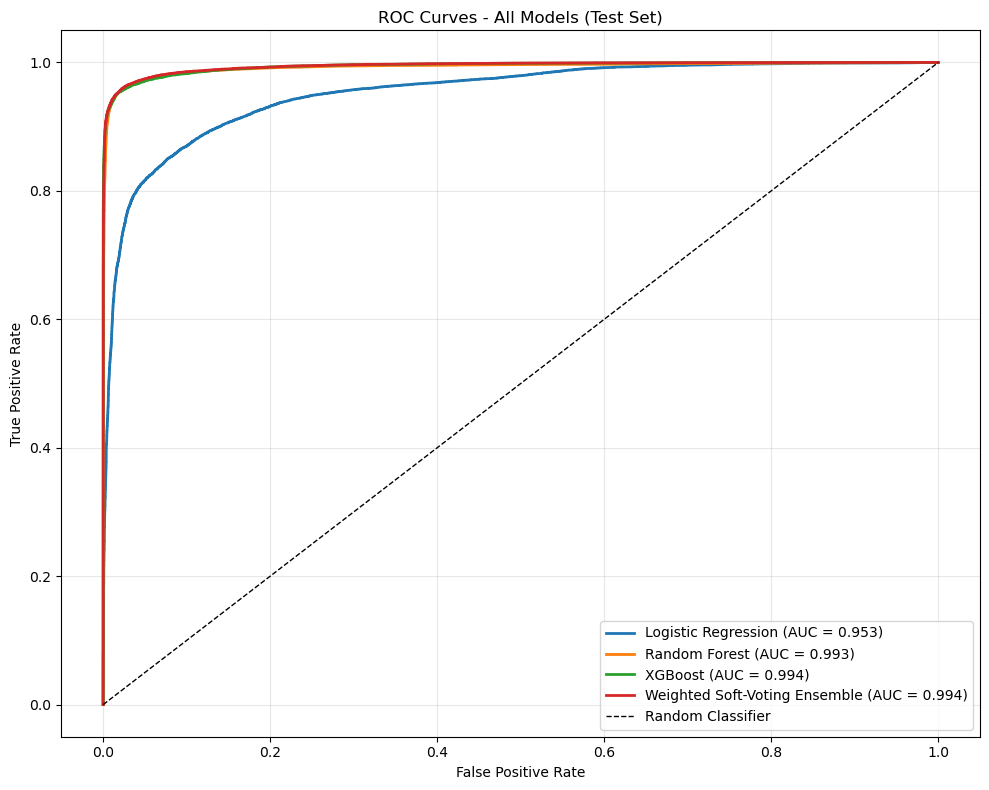

ROC curves saved!


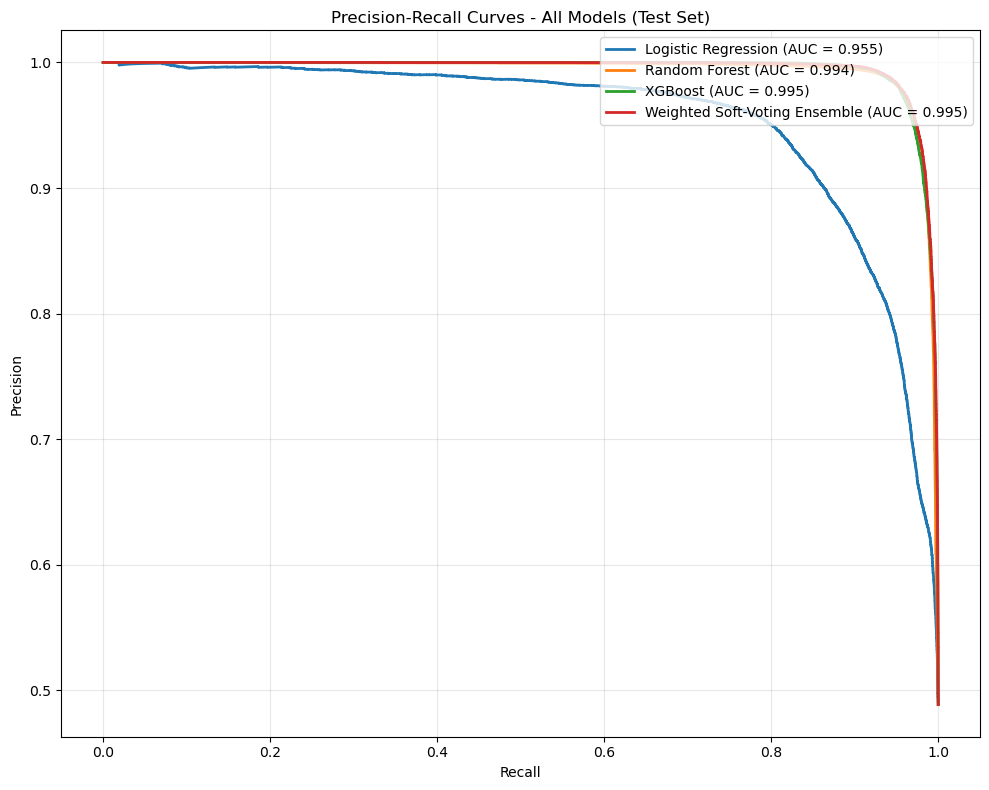

PR curves saved!


In [10]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt

logistic_proba = logistic_pipeline.predict_proba(X_test)[:, 1]
rf_proba = random_forest_pipeline.predict_proba(X_test)[:, 1]
xgb_proba = xgboost_pipeline.predict_proba(X_test)[:, 1]
ensemble_proba = hybrid_ensemble.predict_proba(X_test)[:, 1]

# CORRECT: y_test is already numeric
y_test_numeric = y_test.astype(int)

models_proba = {
    'Logistic Regression': logistic_proba,
    'Random Forest': rf_proba,
    'XGBoost': xgb_proba,
    'Weighted Soft-Voting Ensemble': ensemble_proba
}

# Plot ROC curves
fig, ax = plt.subplots(figsize=(10, 8))

for model_name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test_numeric, proba)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.3f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - All Models (Test Set)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / "results/figures/roc_curves.png", dpi=300, bbox_inches='tight')
plt.show()

print("ROC curves saved!")

# Plot PR curves
fig, ax = plt.subplots(figsize=(10, 8))

for model_name, proba in models_proba.items():
    precision, recall, _ = precision_recall_curve(y_test_numeric, proba)
    pr_auc = auc(recall, precision)
    ax.plot(recall, precision, label=f'{model_name} (AUC = {pr_auc:.3f})', linewidth=2)

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves - All Models (Test Set)')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / "results/figures/pr_curves.png", dpi=300, bbox_inches='tight')
plt.show()

print("PR curves saved!")